In [1]:
%matplotlib inline

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime
from pathlib import Path
import sqlite3
import shutil

import openstudio

In [3]:
mpl.rcParams['figure.figsize'] = (16.0, 9.0)

In [4]:
from openstudio.openstudiomodel import *

In [5]:
OUT_DIR = Path('test_schedules')
if OUT_DIR.is_dir():
    shutil.rmtree(OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

## Constants

In [6]:
SCHEDULE_CHANGES = [pd.to_datetime('2009-01-01 8:05:00'), pd.to_datetime('2009-01-01 21:45:00')]
SCH_MIN = 0.1 # Not setting to 0.0 because E+ throws a dumb fatal due to rounding error
SCH_MAX = 1.0
SCH_VALS = [SCH_MIN, SCH_MAX]
assert len(SCHEDULE_CHANGES) == len(SCH_VALS)

TIMESTEPS = [1, 2, 3, 4, 5, 6, 10, 12, 15, 20, 30, 60]
INTERP_METHODS = ["Average", "Linear", "No"]
SCH_RULESET_NAME = "ExteriorEqSch"
SCH_DAY_NAME = f"{SCH_RULESET_NAME}_ScheduleDay"

## Helper to prepare an IDF

In [7]:
def create_test(num_timesteps_per_hour: int, interp_method: str, verbose: bool = False):

    if not num_timesteps_per_hour in TIMESTEPS:
        raise ValueError(f"{num_timesteps_per_hour=} is not in {TIMESTEPS}")
    if not interp_method in INTERP_METHODS:
        raise ValueError(f"{interp_method=} is not in {INTERP_METHODS}")
    m = Model()

    # Set to 1 day
    r = m.getRunPeriod()
    r.setEndMonth(1)
    r.setEndDayOfMonth(1)

    timestep = m.getTimestep()
    timestep.setNumberOfTimestepsPerHour(num_timesteps_per_hour)
    
    sch_ruleset = ScheduleRuleset(m)
    sch_ruleset.setName(SCH_RULESET_NAME)
    
    # Use the schedule so it gets translated
    ed = ExteriorFuelEquipmentDefinition(m)
    ed.setDesignLevel(100.0)
    e = ExteriorFuelEquipment(ed)
    e.setSchedule(sch_ruleset)
    
    sch_day = sch_ruleset.defaultDaySchedule()
        
    for t, val in zip(SCHEDULE_CHANGES, SCH_VALS):
        sch_day.addValue(openstudio.Time(0, t.hour, t.minute, t.second), val)
    sch_day.addValue(openstudio.Time(0, 24, 0, 0), SCH_VALS[0])
    sch_day.setName(SCH_DAY_NAME)
    
    if interp_method == "Average":
        sch_day.setInterpolatetoTimestep(True)
    elif interp_method == "No":
        sch_day.setInterpolatetoTimestep(False)
    else:
        if verbose:
            print(f"{interp_method} not supported by E+, will set during FT")
    
    
    out_var = OutputVariable("Schedule Value", m)
    out_var.setReportingFrequency("Timestep")
    out_var.setKeyValue(sch_ruleset.nameString())
    
    
    ft = openstudio.energyplus.ForwardTranslator()
    ft.setExcludeHTMLOutputReport(True)
    ft.setExcludeLCCObjects(True)
    ft.setKeepRunControlSpecialDays(False)
    logLevel = openstudio.Logger.instance().standardOutLogger().logLevel().get()
    openstudio.Logger.instance().standardOutLogger().setLogLevel(openstudio.Fatal)
    w = ft.translateModel(m)
    openstudio.Logger.instance().standardOutLogger().setLogLevel(logLevel)

    if interp_method == 'Linear':
        schs = w.getObjectsByTypeAndName('Schedule:Day:Interval', SCH_DAY_NAME)
        assert len(schs) == 1
        i_sch = schs[0]
        i_sch.setString(2, "Linear")
        if verbose:
            print(i_sch)
        
    idf_path = OUT_DIR / f"{interp_method}-{num_timesteps_per_hour}.idf"
    w.save(idf_path, True)

    return m, w, idf_path

In [8]:
m, w, idf_path = create_test(num_timesteps_per_hour=6, interp_method="Average", verbose=False)
print(idf_path)
print(m.getTimestep())
print(w.getObjectsByTypeAndName('Schedule:Day:Interval', SCH_DAY_NAME)[0])

test_schedules/Average-6.idf
OS:Timestep,
  {6cbc0169-fd7e-4d09-8eac-817f52c3c2b1}, !- Handle
  6;                                      !- Number of Timesteps per Hour


Schedule:Day:Interval,
  ExteriorEqSch_ScheduleDay,              !- Name
  Fractional,                             !- Schedule Type Limits Name
  Average,                                !- Interpolate to Timestep
  08:05,                                  !- Time 1 {hh:mm}
  0.1,                                    !- Value Until Time 1
  21:45,                                  !- Time 2 {hh:mm}
  1,                                      !- Value Until Time 2
  24:00,                                  !- Time 3 {hh:mm}
  0.1;                                    !- Value Until Time 3




## Class to prepare a model and run E+ via API, with methods to plot

In [9]:
# insert the repo build tree or install path into the search Path, then import the EnergyPlus API
sys.path.insert(0, '/Applications/EnergyPlus-23-2-0')
from pyenergyplus.api import EnergyPlusAPI

In [10]:
EnergyPlusAPI.api_version()

'0.2'

In [11]:
EPW_FILE = '/Applications/EnergyPlus-23-2-0/WeatherData/USA_CO_Golden-NREL.724666_TMY3.epw'

In [12]:
class ScheduleValueGrabber:

    def __init__(self, api, num_timesteps_per_hour: int, interp_method: str, verbose: bool = False):
        
        self.num_timesteps_per_hour = num_timesteps_per_hour
        self.interp_method = interp_method
        self.verbose = verbose
        
        m, w, idf_path = create_test(
            num_timesteps_per_hour=self.num_timesteps_per_hour, 
            interp_method=self.interp_method,
            verbose=self.verbose,
        )
        self.model = m
        self.workspace = w
        self.idf_path = idf_path
        self.out_dir = idf_path.parent / f"out-{idf_path.stem}"
        self.sql_file = self.out_dir / "eplusout.sql"
        
        self.api = api
        self.state = None
        
        self.need_to_get_handles = True
        self.schedule_handle = None
        self.times = []
        self.values = []
        self.time_index = []
        
    def _callback_begin_system_timestep_before_predictor(self, state) -> int:
        if not self.api.exchange.api_data_fully_ready(state):
            return 0
        if self.api.exchange.warmup_flag(state):
            return 0
        
        # get handles if needed
        if self.need_to_get_handles:
            self.schedule_handle = self.api.exchange.get_variable_handle(state, "Schedule Value", SCH_RULESET_NAME)
            self.need_to_get_handles = False
            if self.schedule_handle == -1:
                self.api.runtime.issue_severe(state, f"Could not get handle to Schedule {SCH_RULESET_NAME}")
                return 1

        
        calendar_year = self.api.exchange.calendar_year(state)
        year = self.api.exchange.year(state)
        month = self.api.exchange.month(state)
        day = self.api.exchange.day_of_month(state)
        hour = self.api.exchange.hour(state)
        minute = self.api.exchange.minutes(state)
        current_time = self.api.exchange.current_time(state)
        actual_date_time = self.api.exchange.actual_date_time(state)
        actual_time = self.api.exchange.actual_time(state)
        self.times.append(
            {
                "year": year,
                "month": month,
                "day": day,
                "hour": hour,
                "minute": minute,
                "current_time": current_time,
                "actual_date_time": actual_date_time,
                "actual_time": actual_time,       
            }
        )
        self.time_index.append(datetime.datetime(calendar_year, month, day) + datetime.timedelta(hours=current_time))
        
        sch_value = self.api.exchange.get_variable_value(state, self.schedule_handle)
        self.values.append(sch_value)
        
        return 0
    
    def run(self):
        self.state = self.api.state_manager.new_state()
        
        self.api.runtime.set_console_output_status(self.state, print_output=self.verbose)
        
        if svg.out_dir.is_dir():
            shutil.rmtree(self.out_dir)
        
        self.api.runtime.callback_begin_system_timestep_before_predictor(self.state, self._callback_begin_system_timestep_before_predictor)

        return_code = self.api.runtime.run_energyplus(self.state,
            [
                '-w', EPW_FILE,
                '-d', str(self.out_dir),
                str(self.idf_path)
            ]
        )
        # self.api.state_manager.reset_state(self.state)
        self.api.state_manager.delete_state(self.state)
        self.state = None
        
        assert return_code == 0
        
        self.data = pd.Series(
            self.values, 
            # index=pd.timedelta_range(start='0:00:00', freq='10Min', periods=(24 * self.num_timesteps_per_hour))
            # index=pd.date_range(start='1999-01-01 0:00:00', freq='10Min', periods=(24 * self.num_timesteps_per_hour))
            index=self.time_index
        )
        
    def read_error(self):
        print((self.out_dir / 'eplusout.err').read_text())
        
    def plot_schedule_changes(self, axes=None):

        if axes is None:
            fig, axes = plt.subplots(nrows=1, ncols=2, sharex=False, sharey=True)
            axes= axes.flatten()

        for schedule_change, changed_val, ax in zip(SCHEDULE_CHANGES, SCH_VALS, axes):
            i = self.data.index.searchsorted(schedule_change, side='Left')
            if self.data.index[i] > schedule_change:
                n_before = 3
                n_after = 3
            else: # Equality
                n_before = 2
                n_after = 2
            self.data.iloc[i-n_before:i+n_after].plot(ax=ax, marker='o')
            ax.axvline(schedule_change, linestyle='--', color='red')
            ax.scatter([schedule_change], [changed_val], color='red', marker='x')
            
            ax.spines['right'].set_visible(False)
            ax.spines['top'].set_visible(False)
            ax.spines['left'].set_visible(False)
            ax.spines['bottom'].set_visible(False)
            
    def plot(self, ax=None):
        if ax is None:
            fig, ax = plt.subplots()
        self.data.plot(ax=ax, label=f"{self.interp_method} - {self.num_timesteps_per_hour}")
        for schedule_change in SCHEDULE_CHANGES:
            ax.axvline(schedule_change, linestyle='--', color='red')
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        
    def plot_all(self, axes=None, return_axes=False):
        fig = plt.figure()
    
        if axes is None:
            gs1 = mpl.gridspec.GridSpec(2, 2) # , left=0.05, right=0.48, wspace=0.05)
            ax1 = fig.add_subplot(gs1[0, :])
            ax1.set_title(f'Entire day - {self.interp_method} - {self.num_timesteps_per_hour} /hr')
        
            ax2 = fig.add_subplot(gs1[1, 0])
            ax2.set_title(f"Around {SCHEDULE_CHANGES[0].time()}")
            ax3 = fig.add_subplot(gs1[1, 1])
            ax3.set_title(f"Around {SCHEDULE_CHANGES[1].time()}")
        else:
            assert len(axes) == 3
            ax1, ax2, ax3 = axes
        self.plot(ax=ax1)
        self.plot_schedule_changes(axes=[ax2, ax3])
        if return_axes:
            return [ax1, ax2, ax3]
        
    def print_workspace_objects(self):
        print(self.idf_path)
        print(self.model.getTimestep())
        print(self.workspace.getObjectsByTypeAndName('Schedule:Day:Interval', SCH_DAY_NAME)[0])

In [13]:
api = EnergyPlusAPI()

## Test specific timestep

In [14]:
num_timesteps_per_hour = 6

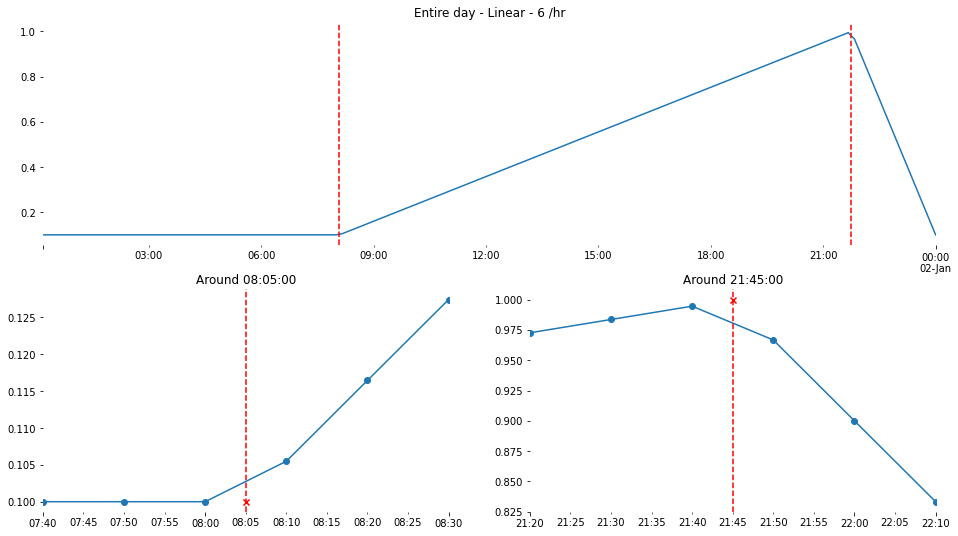

In [15]:
svg = ScheduleValueGrabber(api=api, num_timesteps_per_hour=num_timesteps_per_hour, interp_method="Linear", verbose=False)
svg.run()
# svg.read_error()
svg.plot_all()

In [16]:
svg.print_workspace_objects()

test_schedules/Linear-6.idf
OS:Timestep,
  {a72c8ad8-a95f-4548-a199-c563a38d9221}, !- Handle
  6;                                      !- Number of Timesteps per Hour


Schedule:Day:Interval,
  ExteriorEqSch_ScheduleDay,              !- Name
  Fractional,                             !- Schedule Type Limits Name
  Linear,                                 !- Interpolate to Timestep
  08:05,                                  !- Time 1 {hh:mm}
  0.1,                                    !- Value Until Time 1
  21:45,                                  !- Time 2 {hh:mm}
  1,                                      !- Value Until Time 2
  24:00,                                  !- Time 3 {hh:mm}
  0.1;                                    !- Value Until Time 3




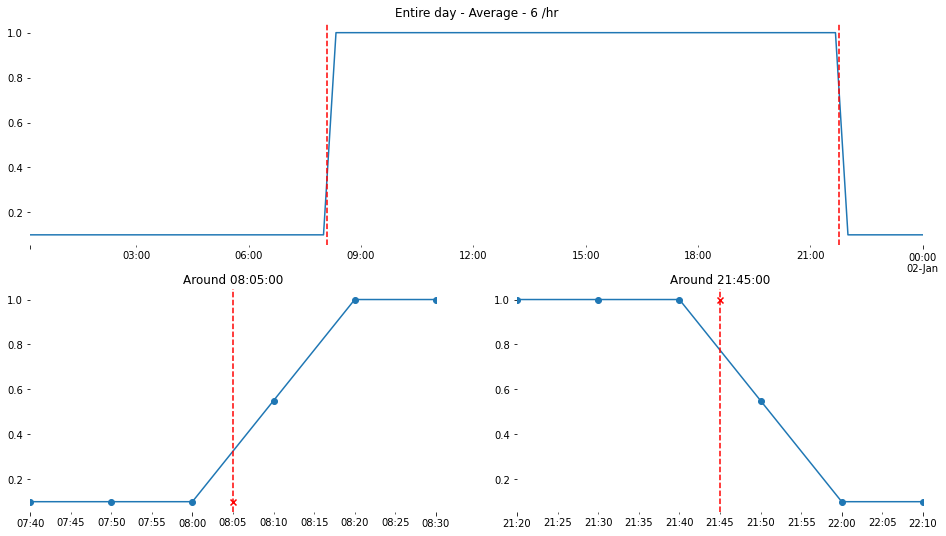

In [17]:
api = EnergyPlusAPI()
svg = ScheduleValueGrabber(api=api, num_timesteps_per_hour=num_timesteps_per_hour, interp_method="Average", verbose=False)
svg.run()
# svg.read_error()
svg.plot_all()

In [18]:
svg.print_workspace_objects()

test_schedules/Average-6.idf
OS:Timestep,
  {f775abbe-4267-4237-bc1e-77cfdd7838cd}, !- Handle
  6;                                      !- Number of Timesteps per Hour


Schedule:Day:Interval,
  ExteriorEqSch_ScheduleDay,              !- Name
  Fractional,                             !- Schedule Type Limits Name
  Average,                                !- Interpolate to Timestep
  08:05,                                  !- Time 1 {hh:mm}
  0.1,                                    !- Value Until Time 1
  21:45,                                  !- Time 2 {hh:mm}
  1,                                      !- Value Until Time 2
  24:00,                                  !- Time 3 {hh:mm}
  0.1;                                    !- Value Until Time 3




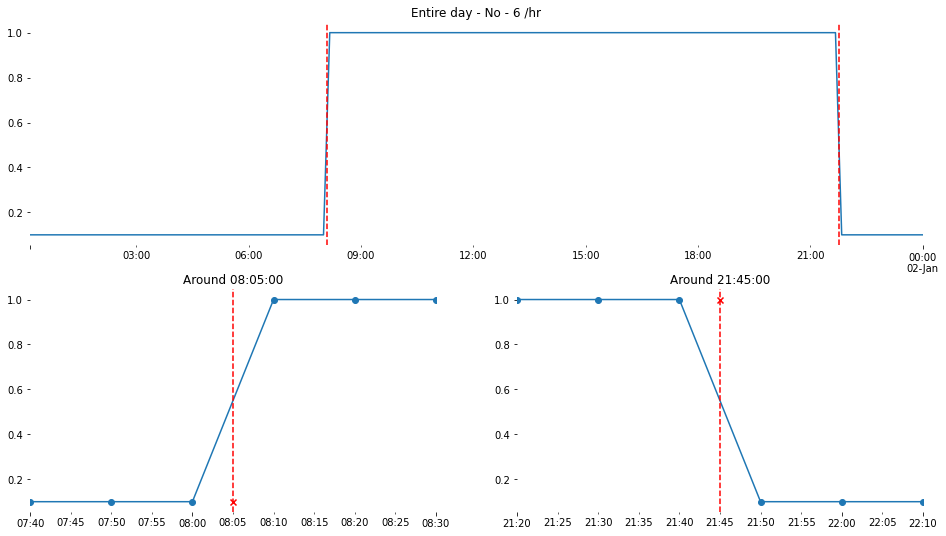

In [19]:
api = EnergyPlusAPI()
svg = ScheduleValueGrabber(api=api, num_timesteps_per_hour=num_timesteps_per_hour, interp_method="No", verbose=False)
svg.run()
# svg.read_error()
svg.plot_all()

In [20]:
svg.print_workspace_objects()

test_schedules/No-6.idf
OS:Timestep,
  {1d33fe0e-3cd0-435c-b59a-fc2e36f3ce14}, !- Handle
  6;                                      !- Number of Timesteps per Hour


Schedule:Day:Interval,
  ExteriorEqSch_ScheduleDay,              !- Name
  Fractional,                             !- Schedule Type Limits Name
  No,                                     !- Interpolate to Timestep
  08:05,                                  !- Time 1 {hh:mm}
  0.1,                                    !- Value Until Time 1
  21:45,                                  !- Time 2 {hh:mm}
  1,                                      !- Value Until Time 2
  24:00,                                  !- Time 3 {hh:mm}
  0.1;                                    !- Value Until Time 3




## Merge into a single graph

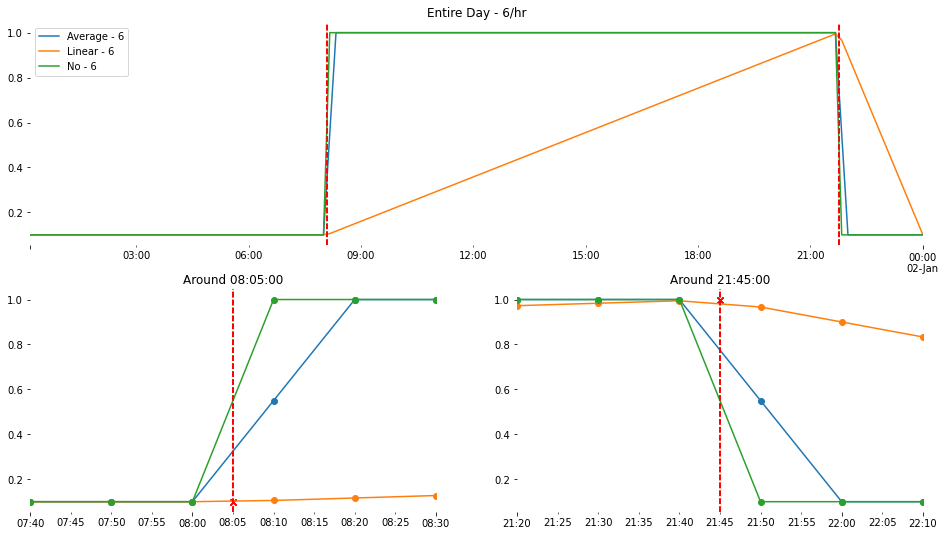

<Figure size 1152x648 with 0 Axes>

<Figure size 1152x648 with 0 Axes>

In [21]:
data_dict = {}
for i, interp_method in enumerate(INTERP_METHODS):
    svg = ScheduleValueGrabber(api=api, num_timesteps_per_hour=num_timesteps_per_hour, interp_method=interp_method, verbose=False)
    svg.run()
    if i == 0:
        axes = svg.plot_all(return_axes=True)
    else:
        svg.plot_all(axes=axes)
    data_dict[interp_method] = svg.data
axes[0].set_title('Entire Day - 6/hr')
axes[0].legend()

In [22]:
df_all = pd.concat(data_dict, axis=1)
df_all[['No', 'Average']].diff(axis=1).max()

No          NaN
Average    0.45
dtype: float64

<AxesSubplot: >

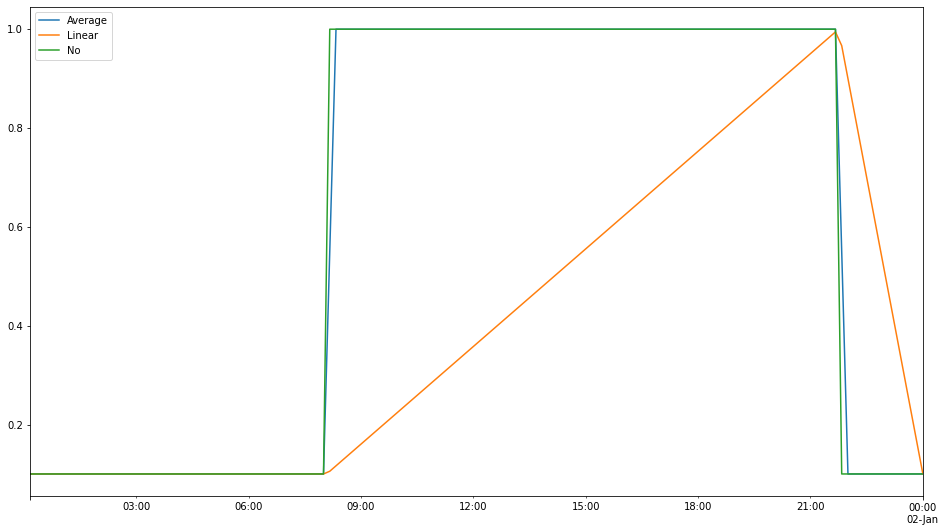

In [23]:
df_all.plot()

## Run All combinations

In [24]:
schedule_grabbers = [
    ScheduleValueGrabber(api=api, num_timesteps_per_hour=t, interp_method=method, verbose=False)
    for t in TIMESTEPS
    for method in INTERP_METHODS
]

/var/folders/bz/sgrc10ls2d9fz7418xw3wgym0000gn/T/ipykernel_82825/2128145397.py:140: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure()


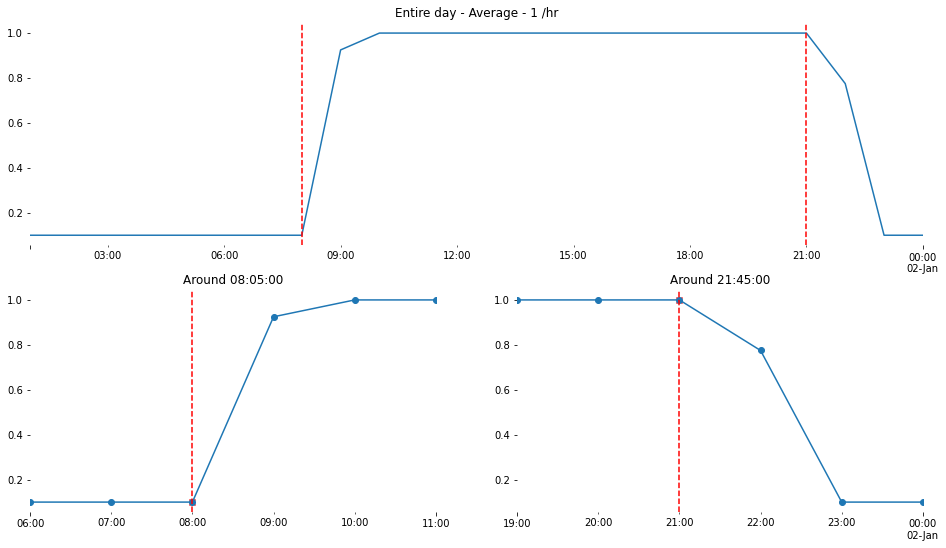

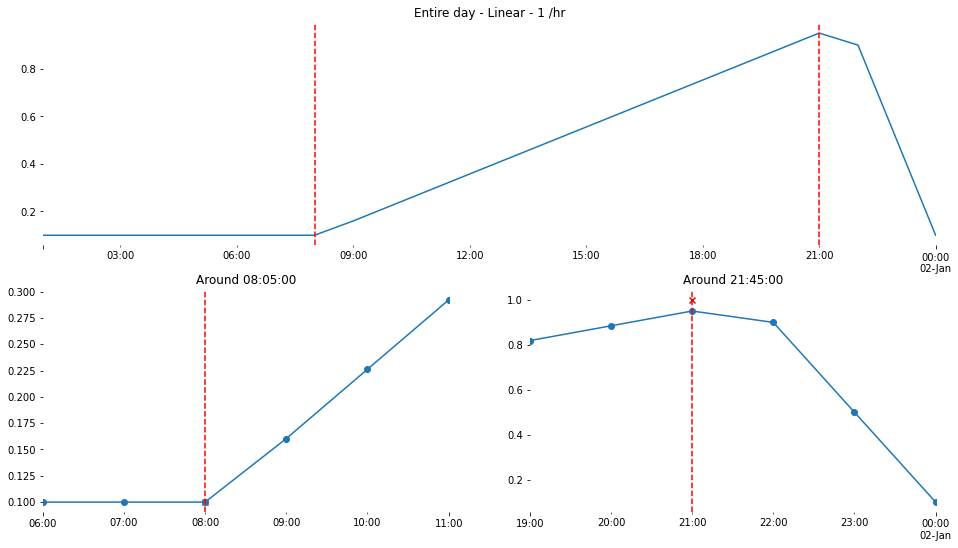

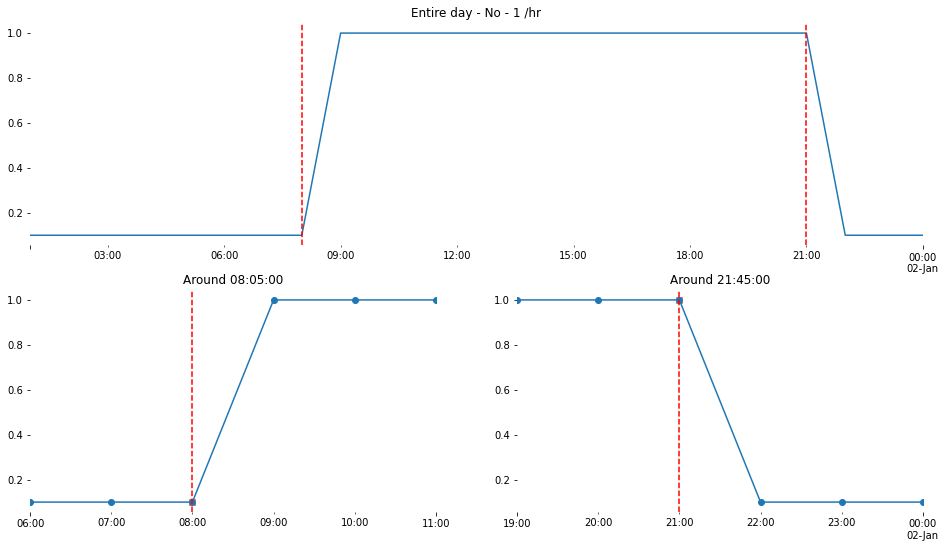

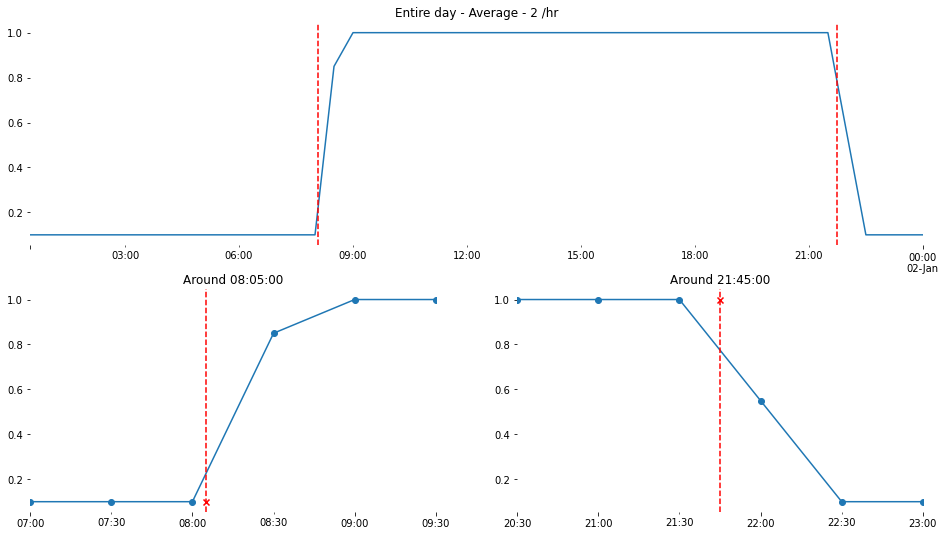

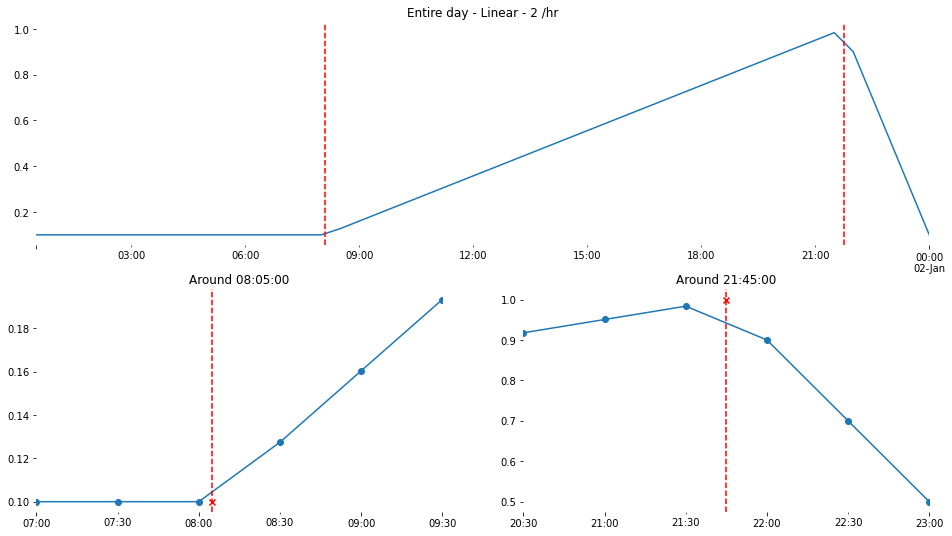

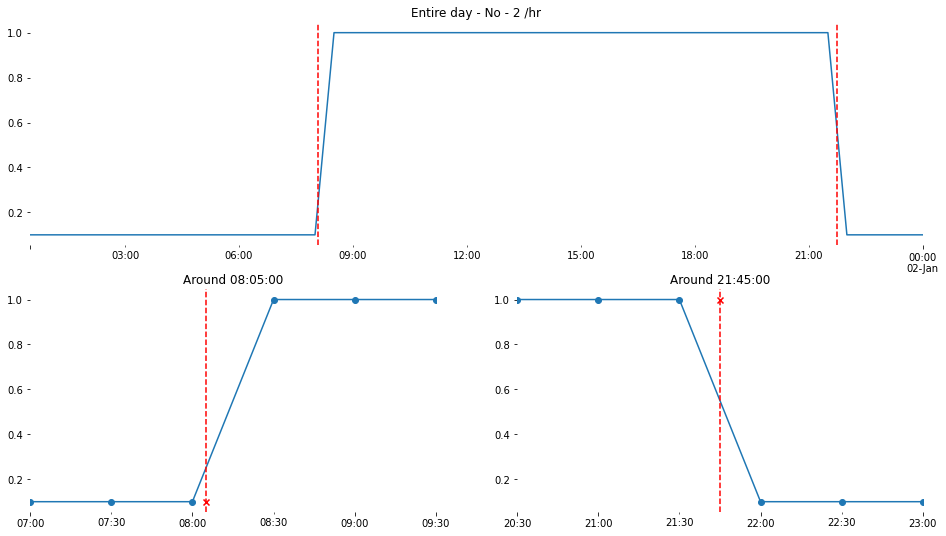

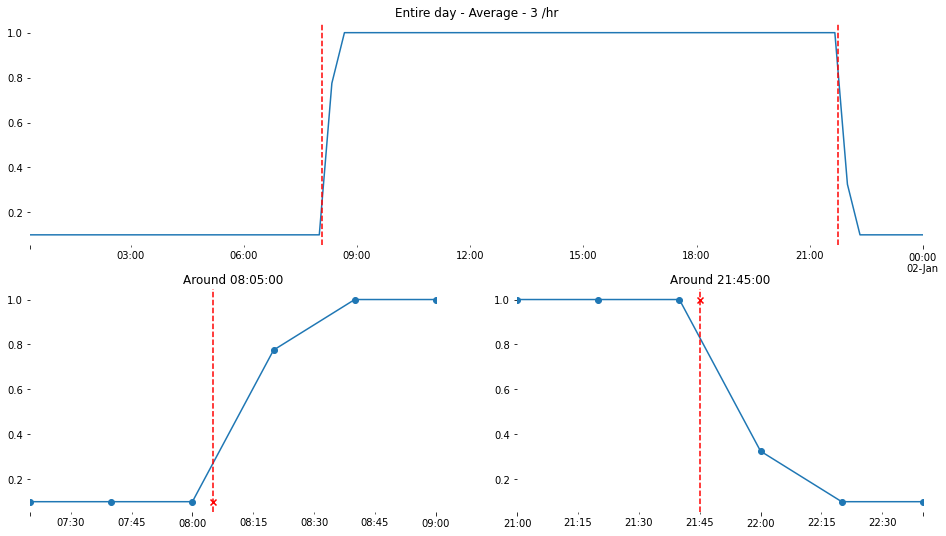

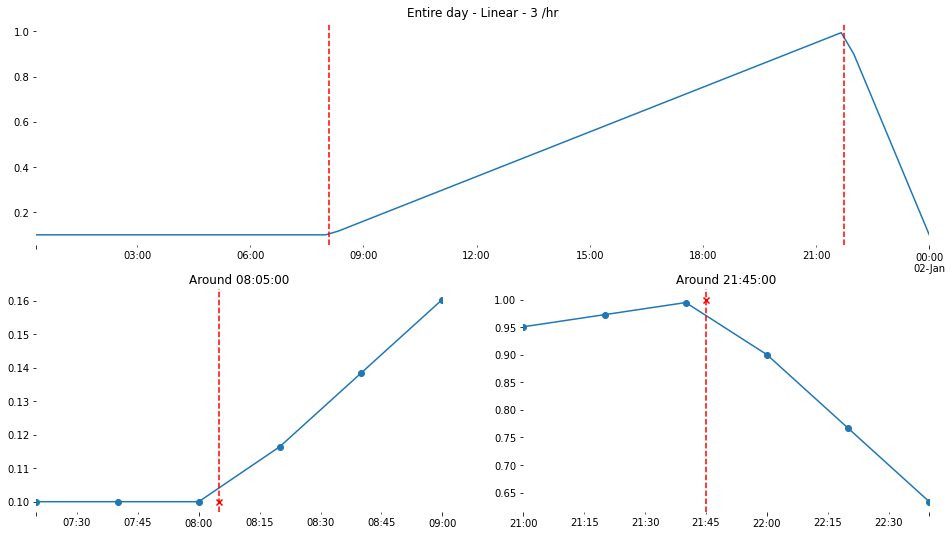

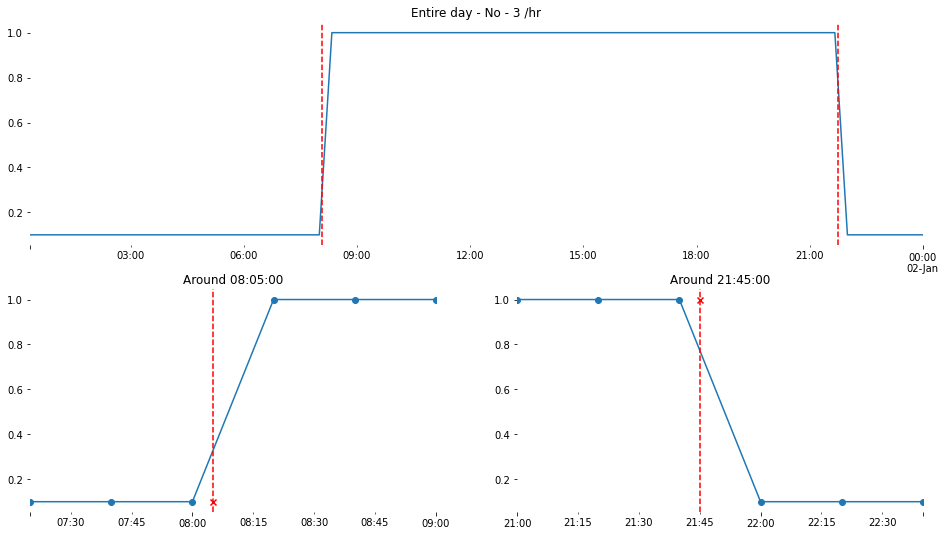

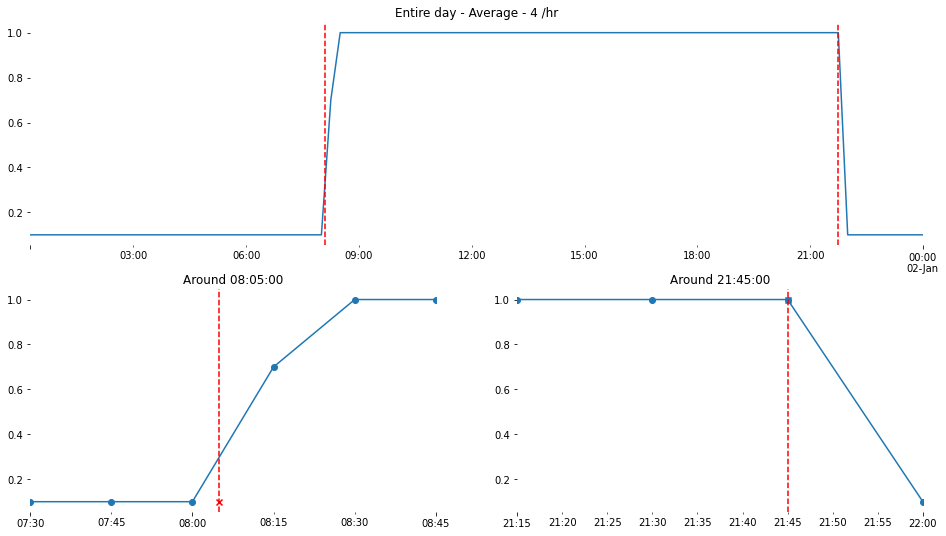

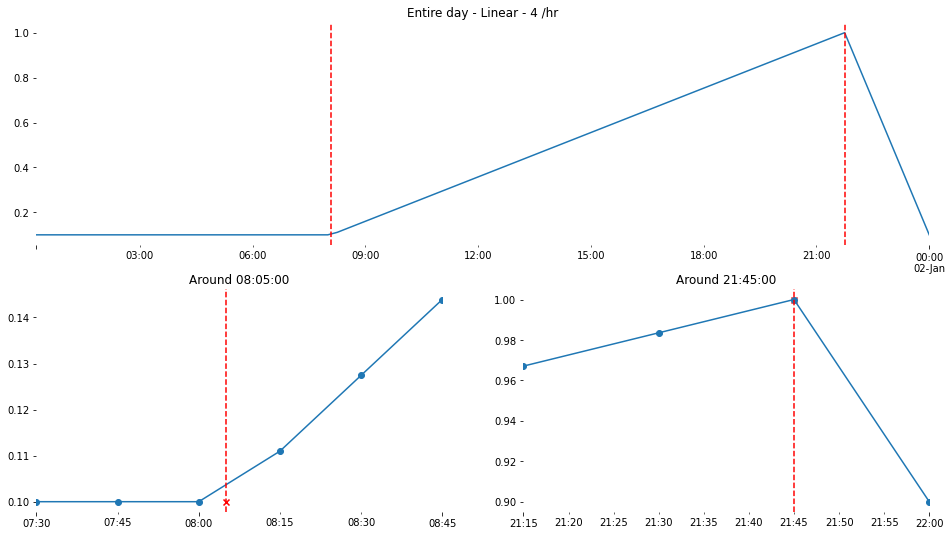

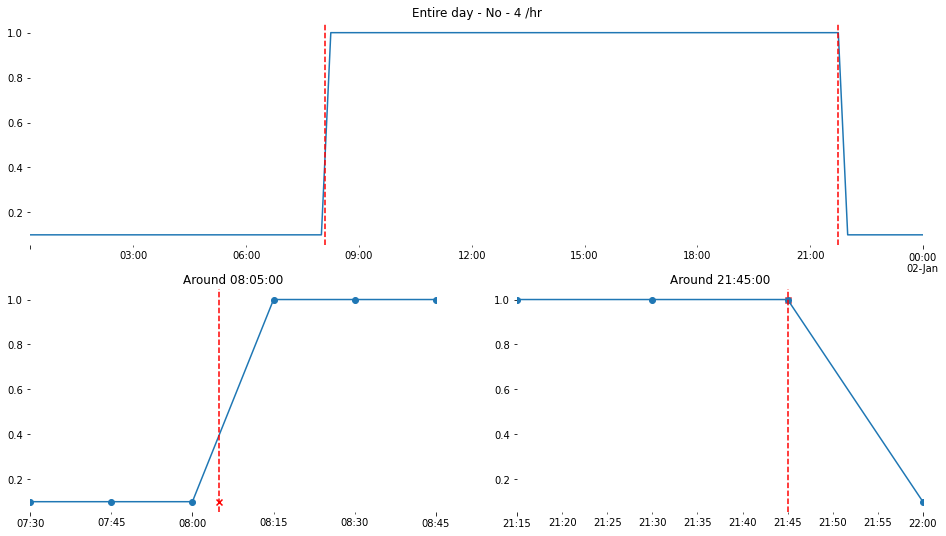

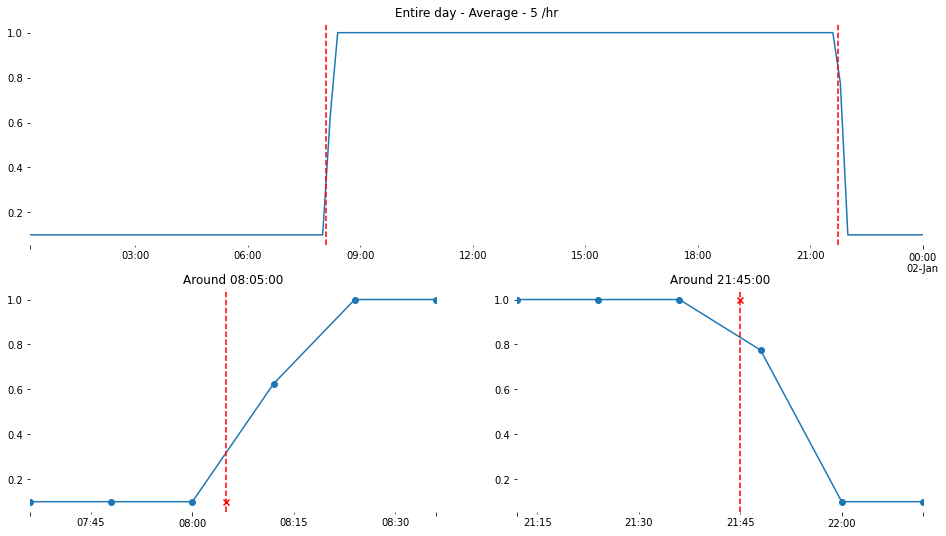

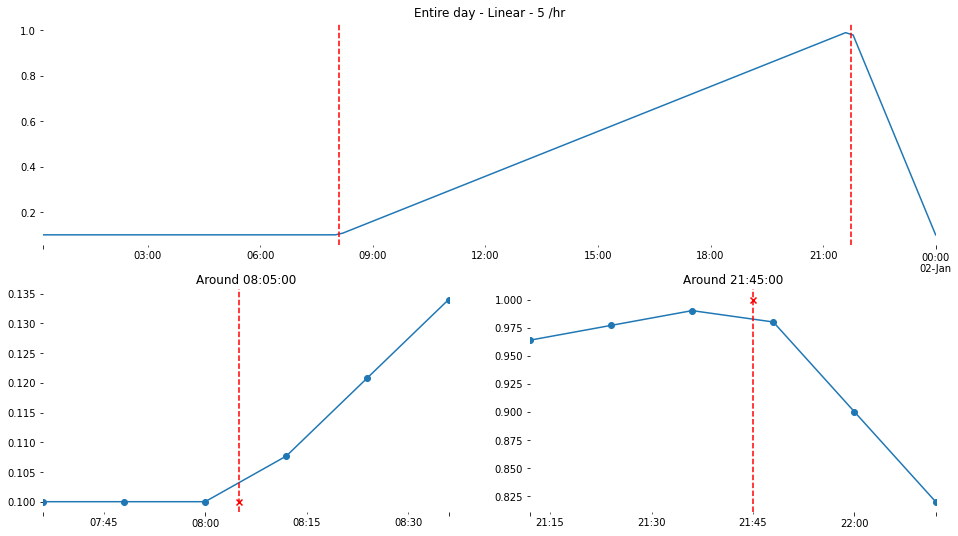

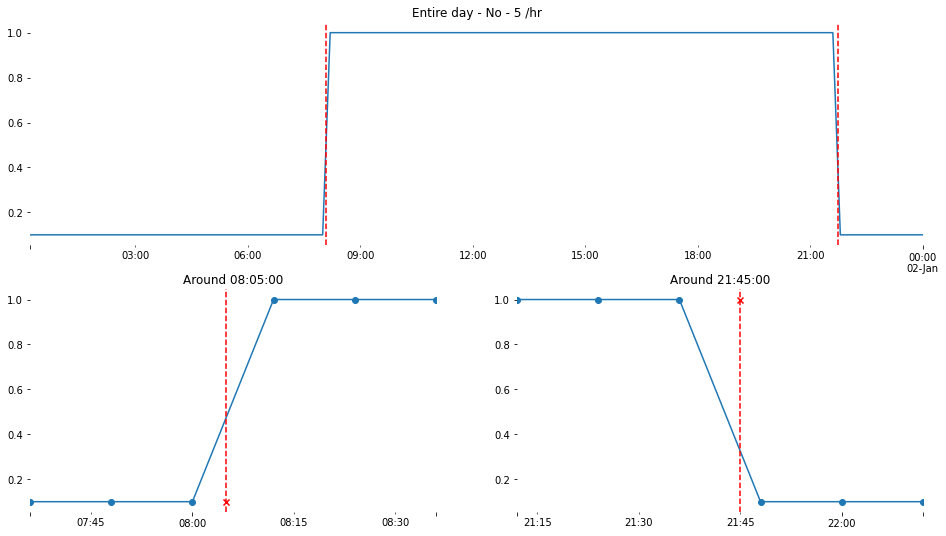

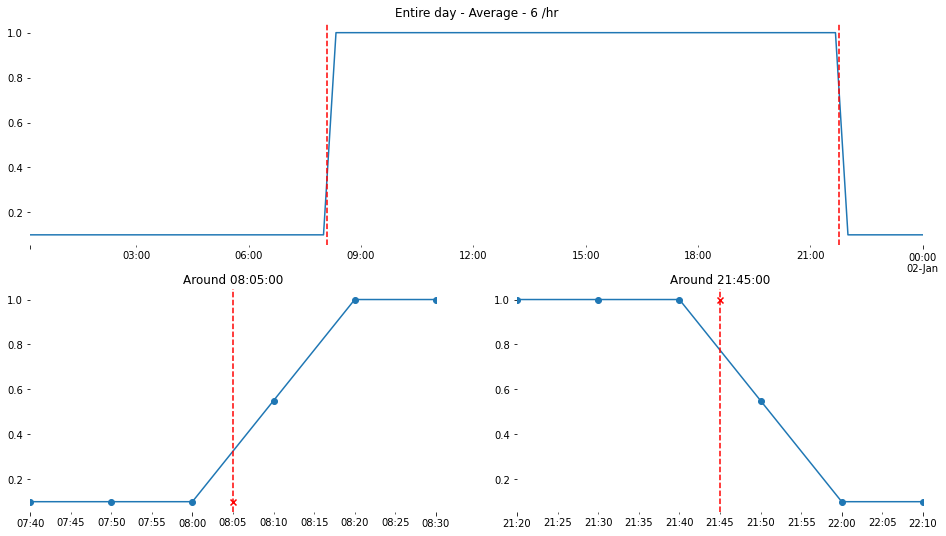

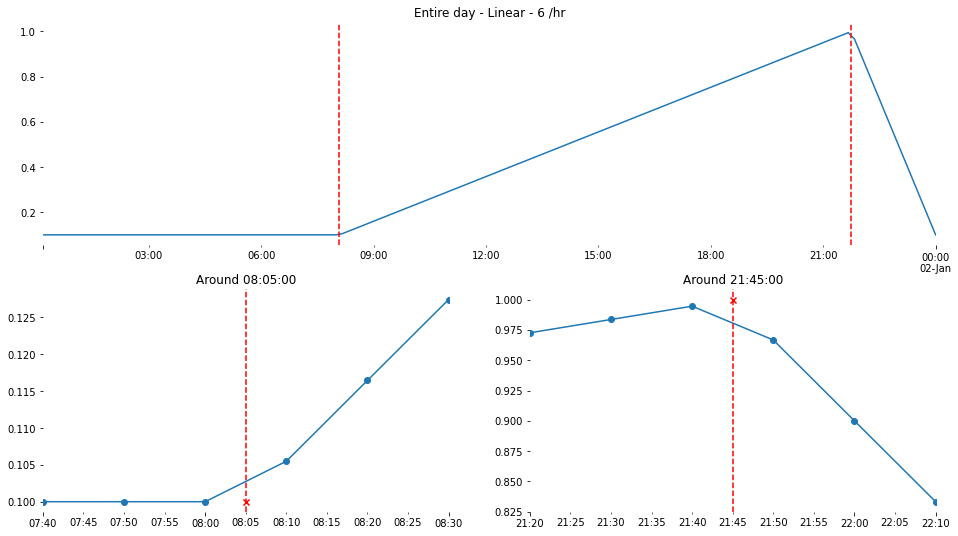

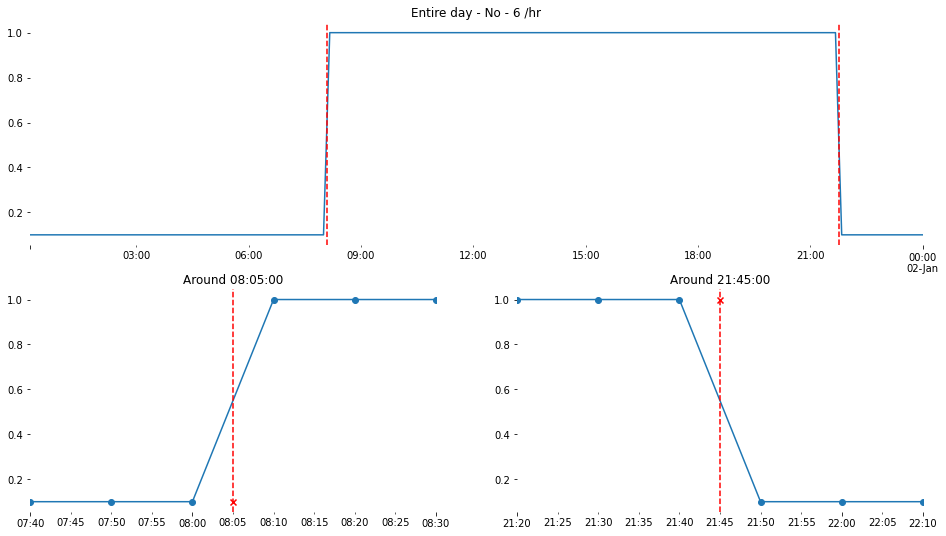

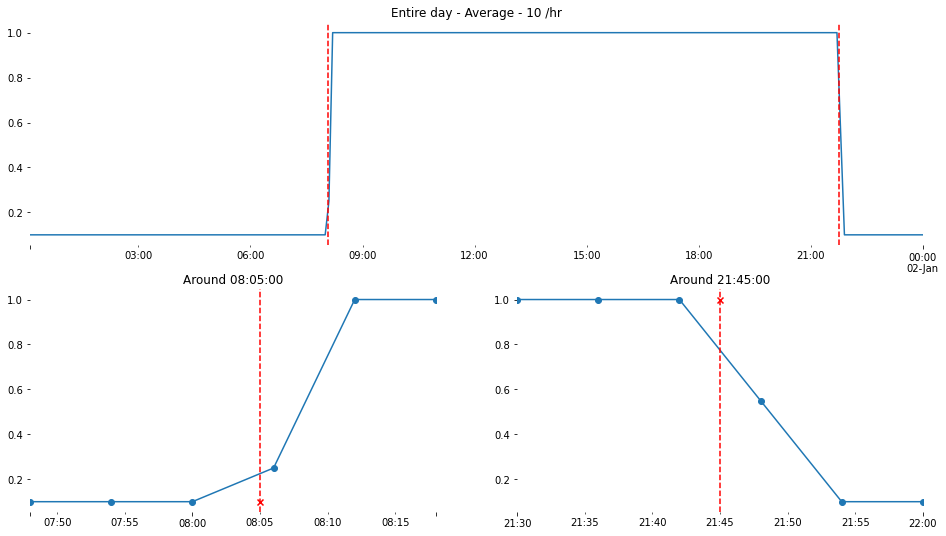

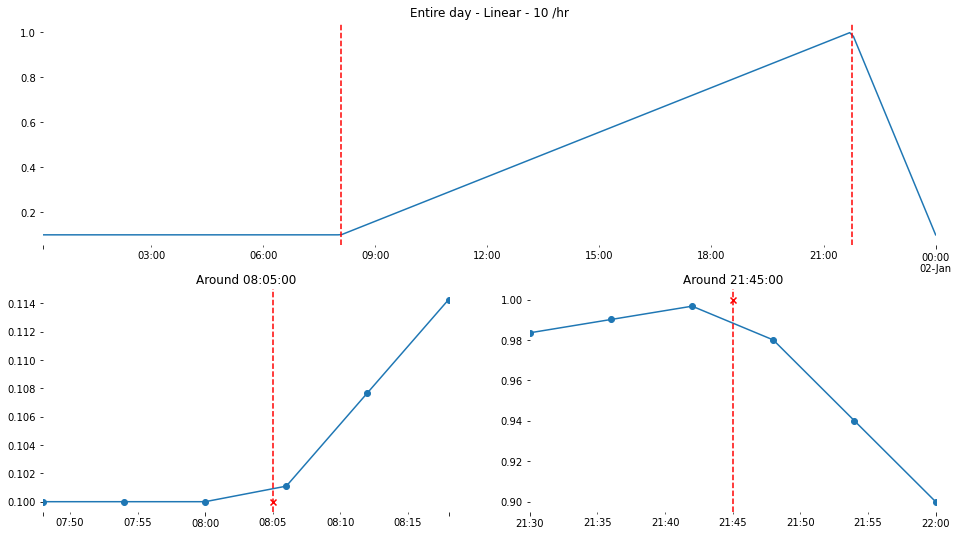

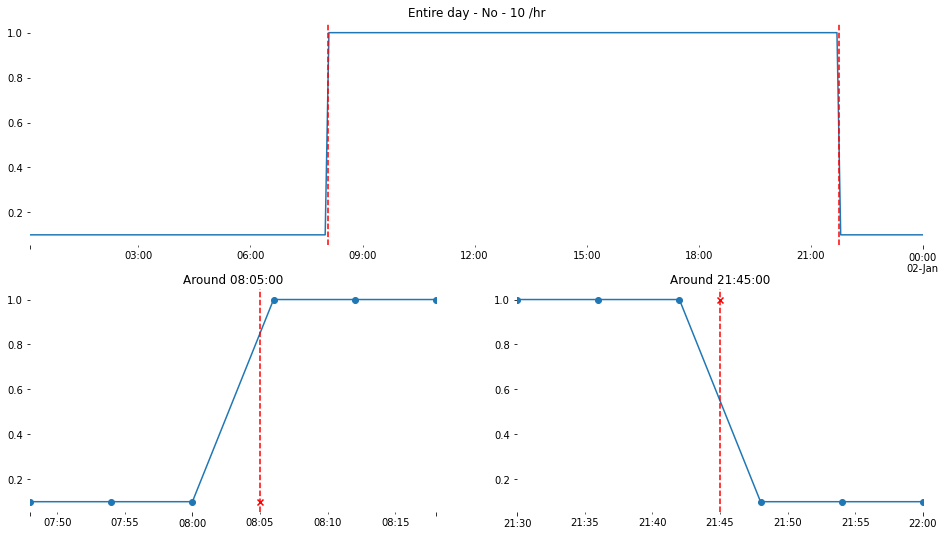

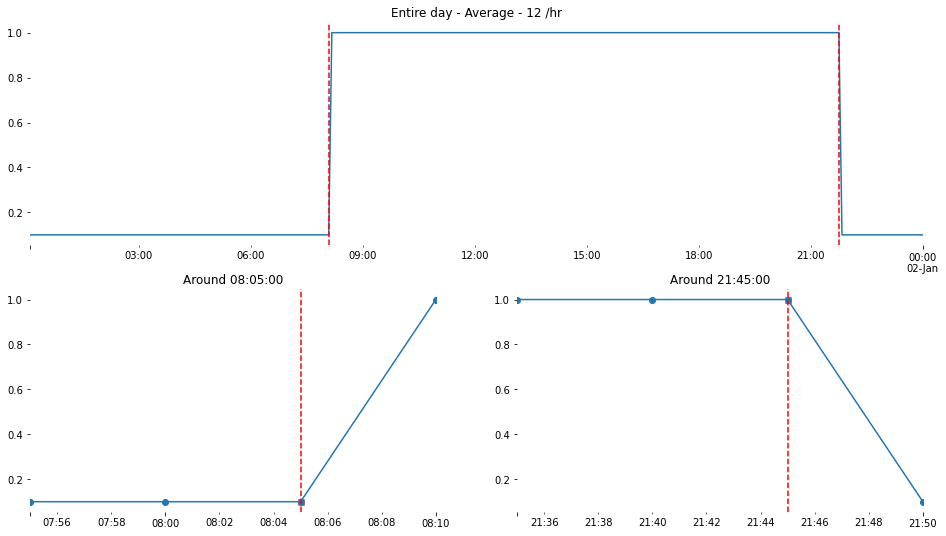

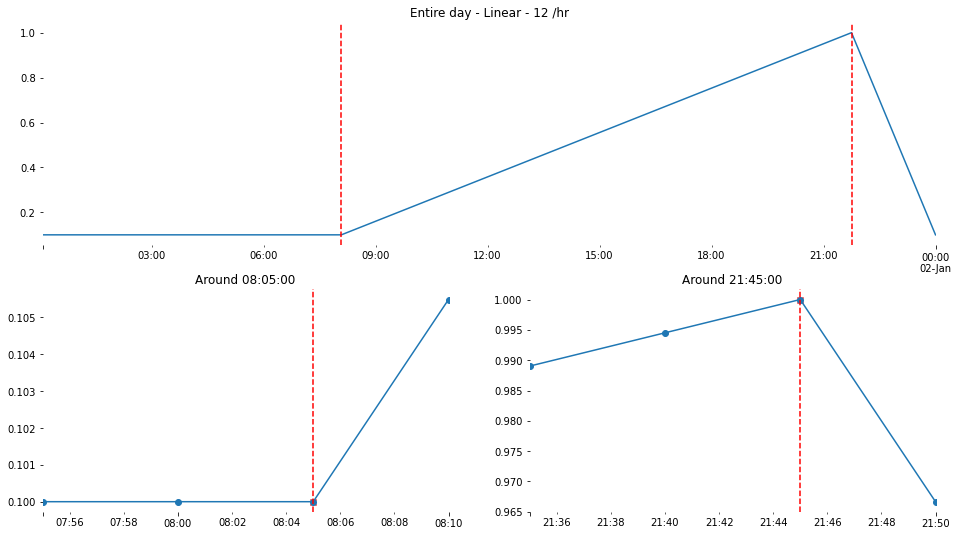

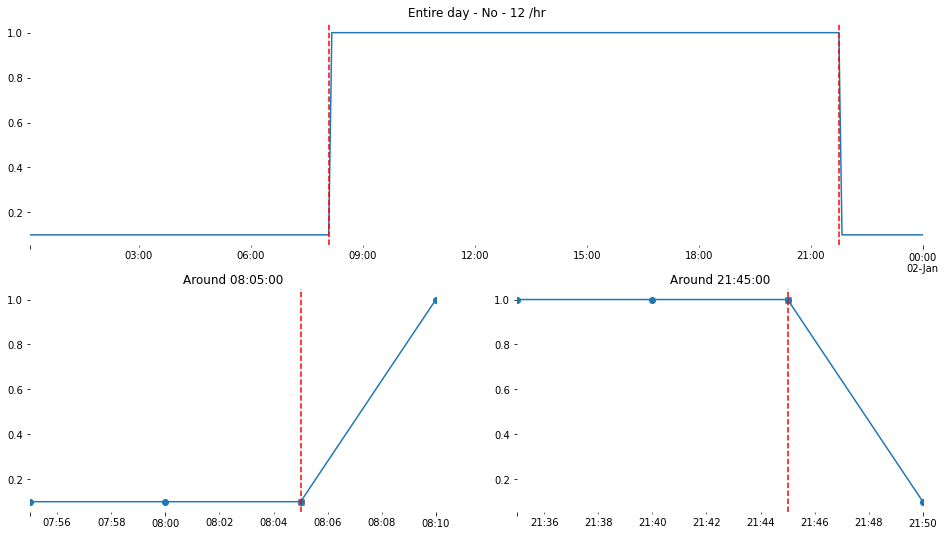

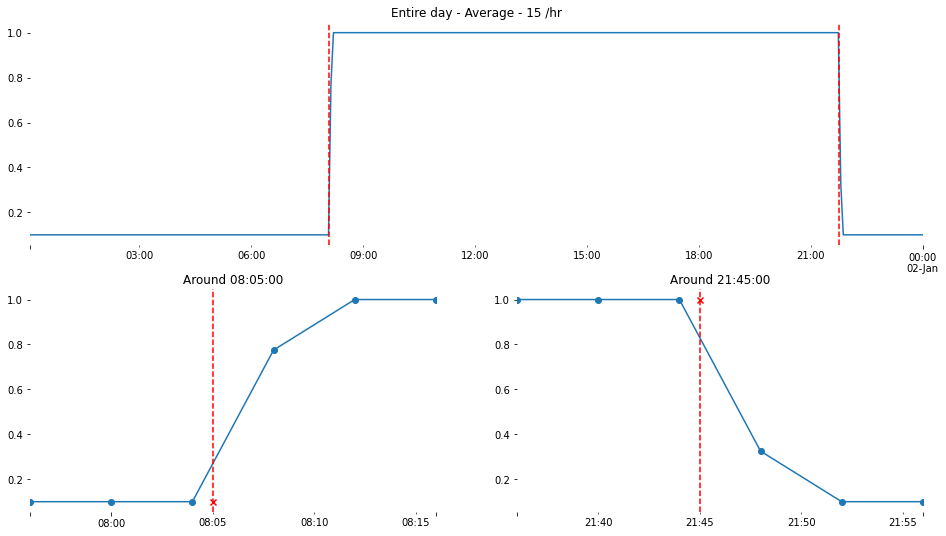

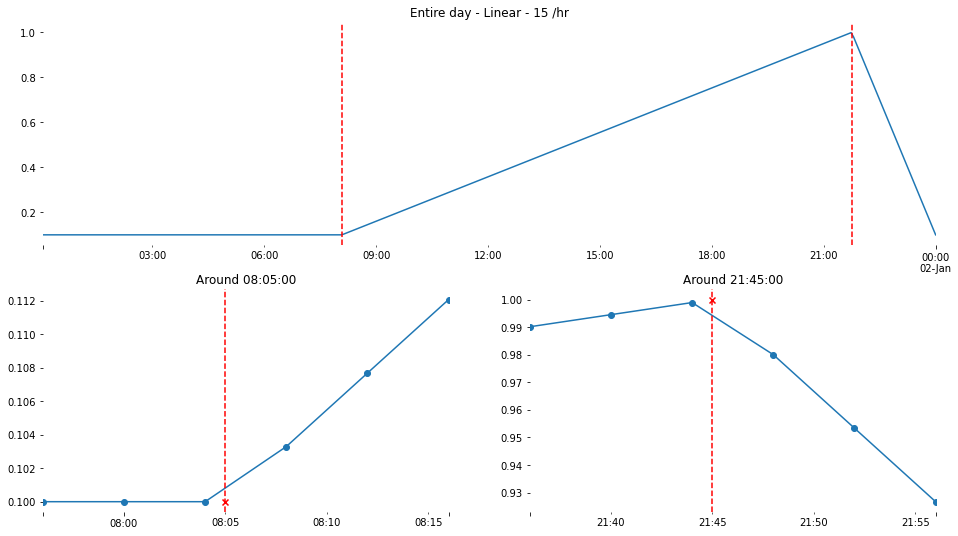

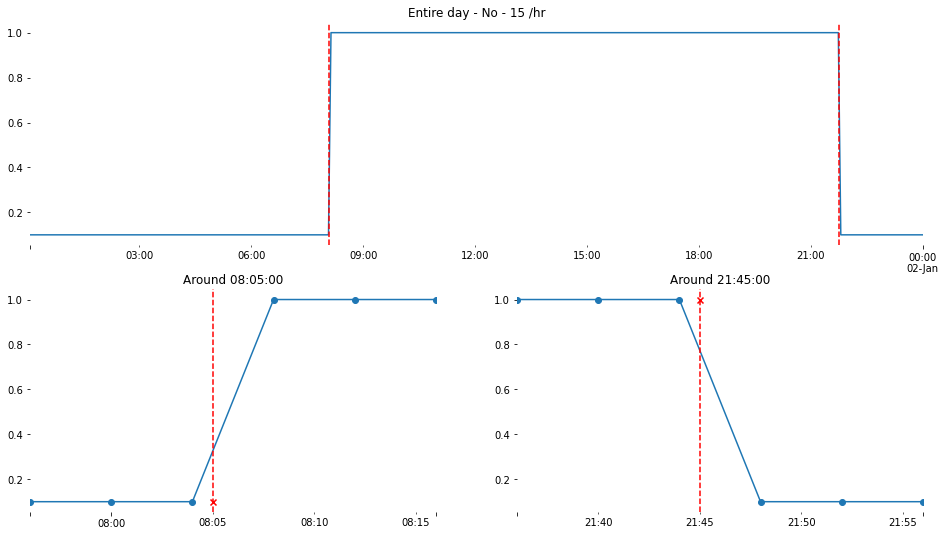

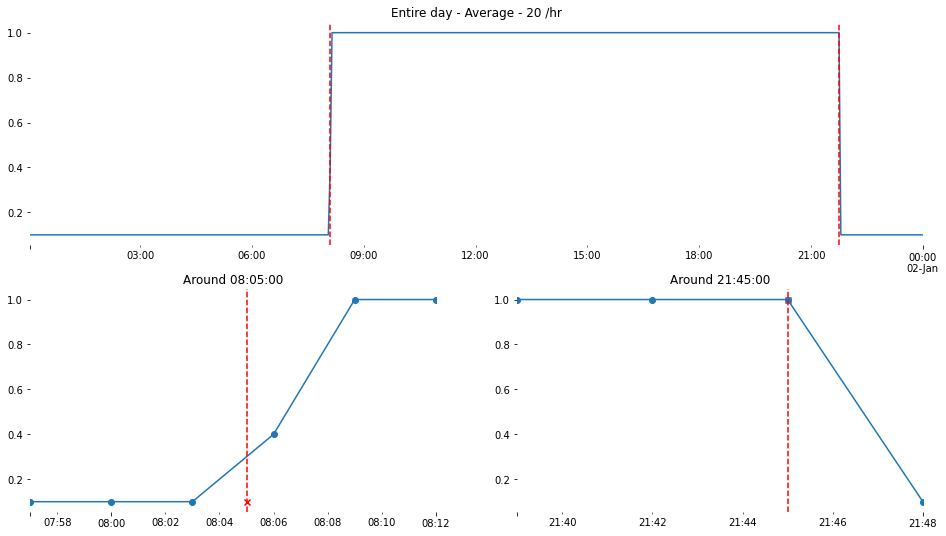

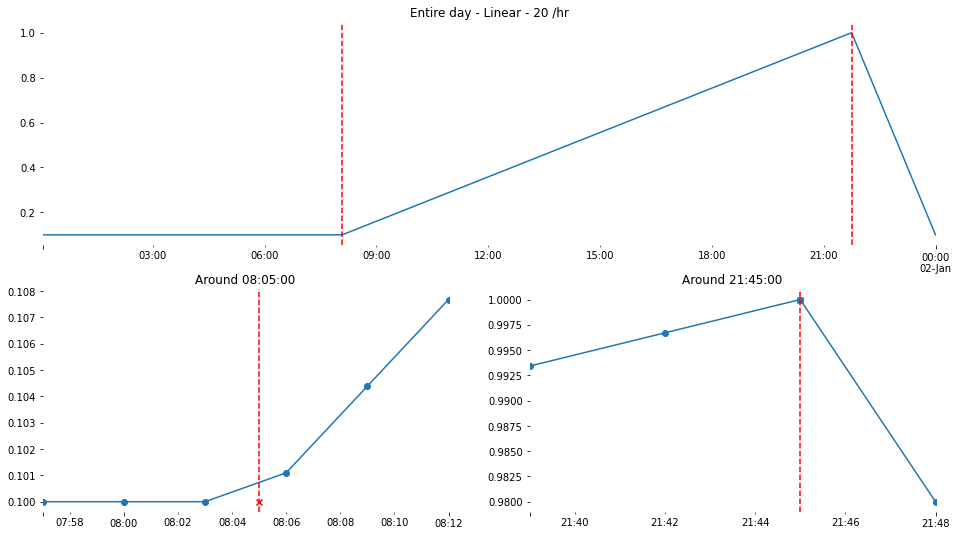

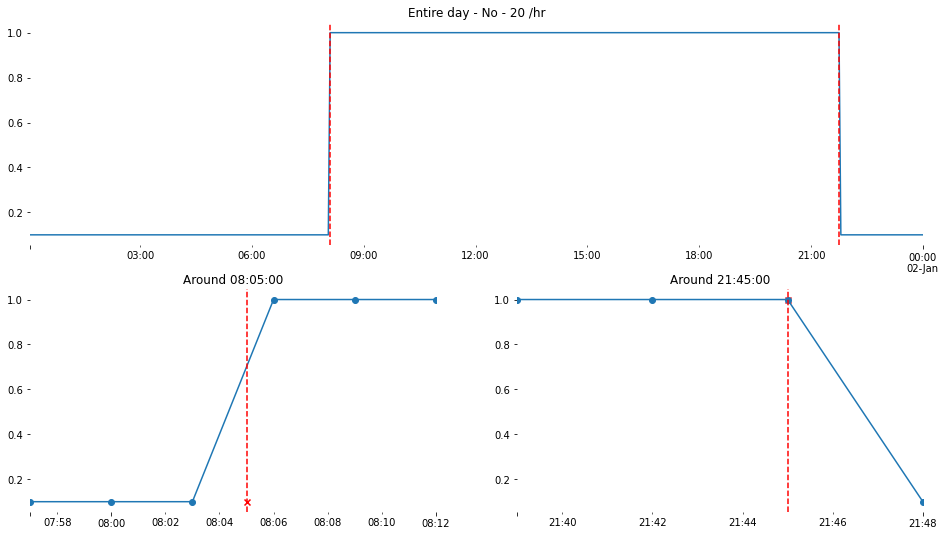

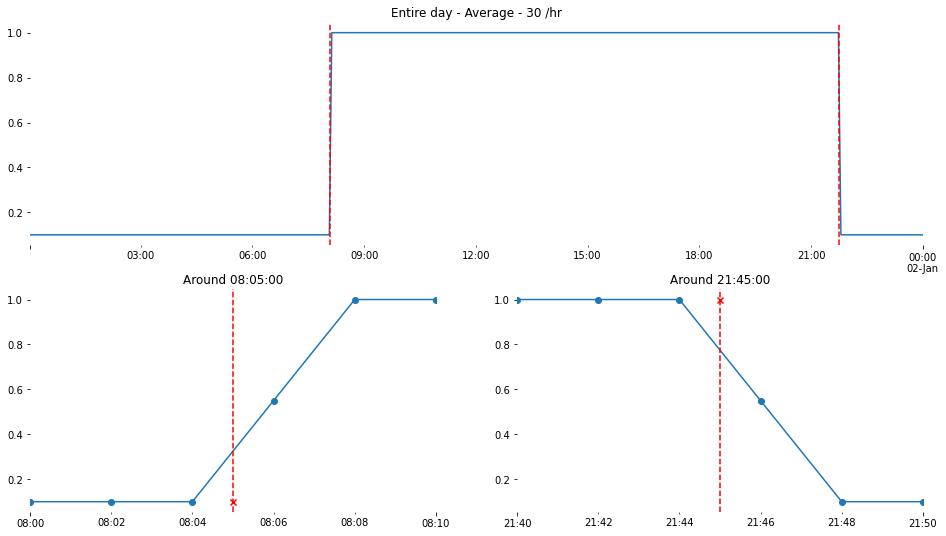

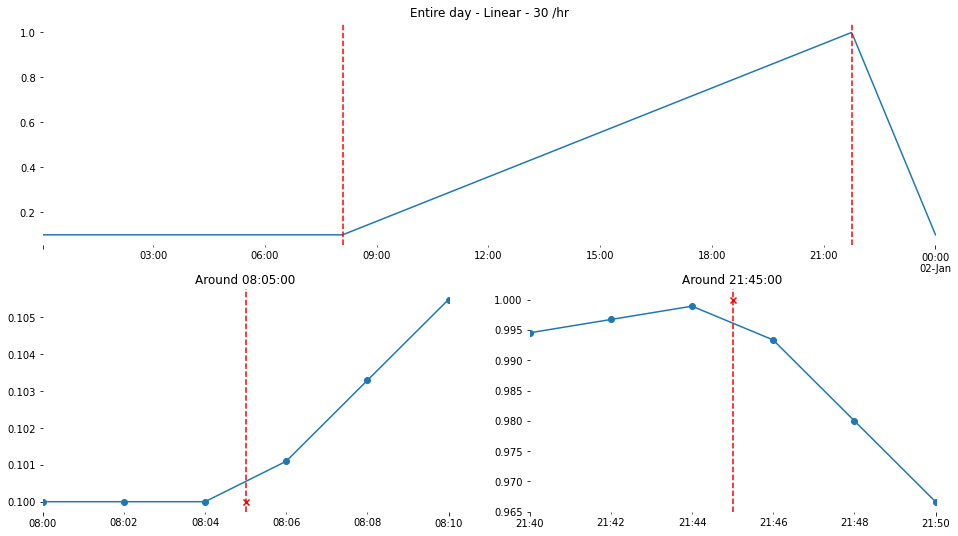

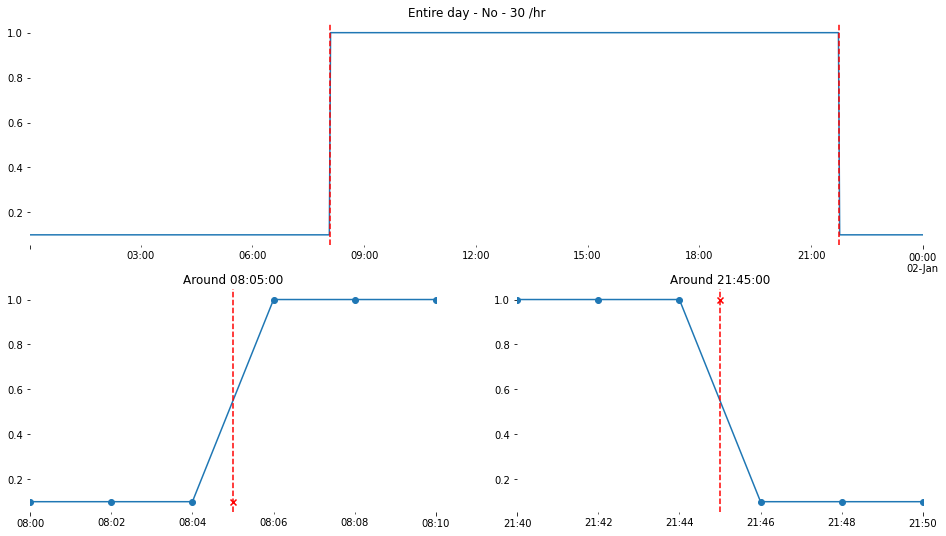

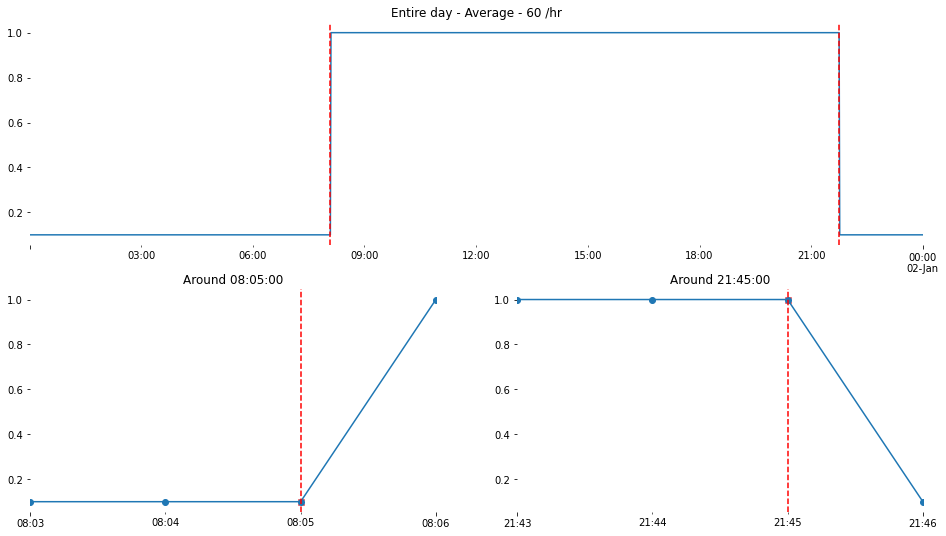

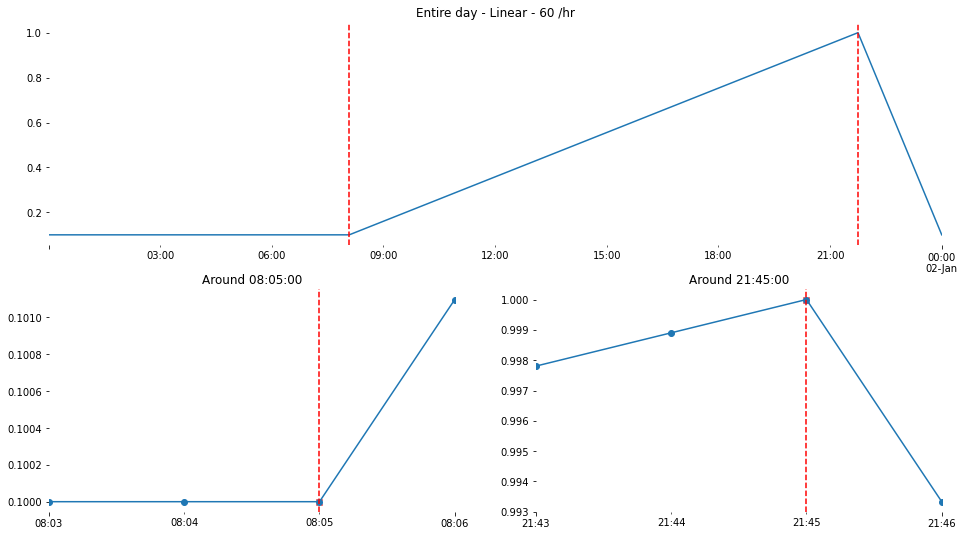

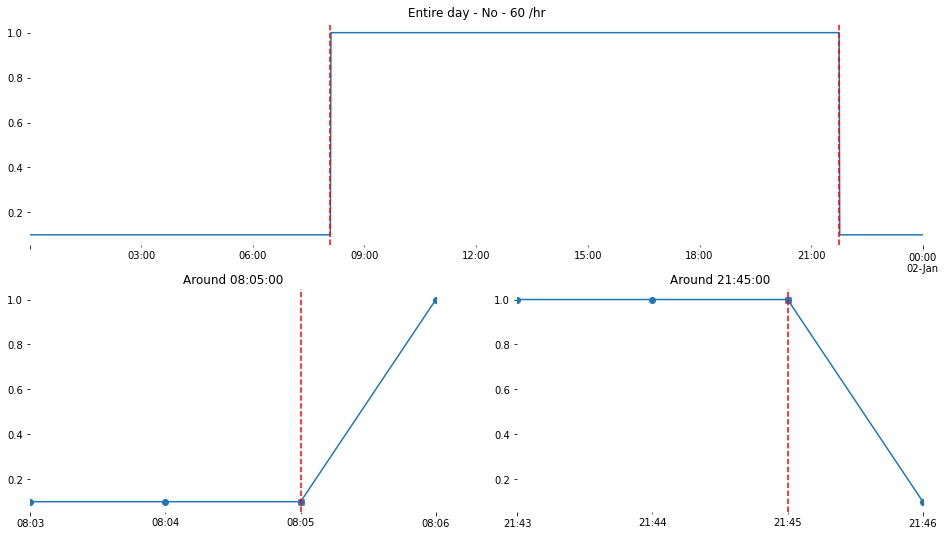

In [25]:
for svg in schedule_grabbers:
    svg.run()
    svg.plot_all()

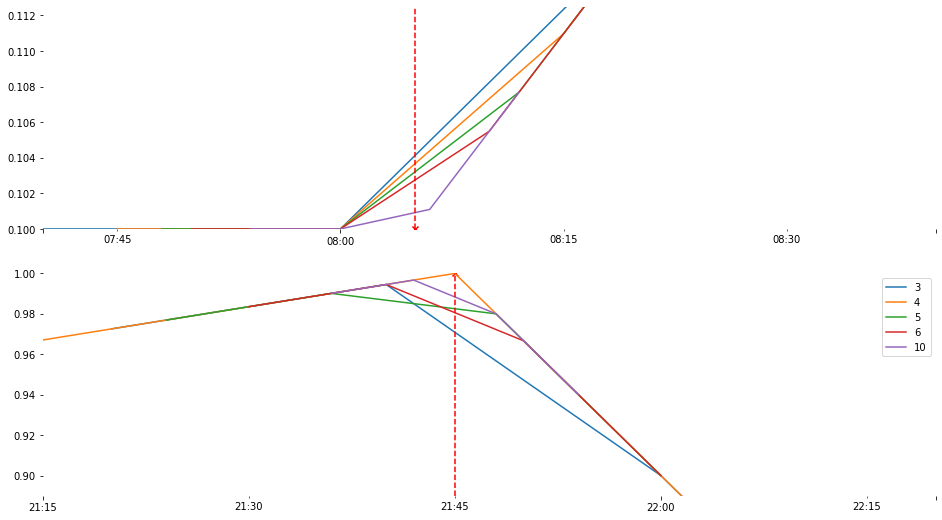

In [26]:
interp_method = 'Linear'

fig, axes = plt.subplots(nrows=2, ncols=1, sharex=False, sharey=False)

for idx, svg in enumerate(schedule_grabbers):
    if svg.interp_method != interp_method:
        continue
    if svg.num_timesteps_per_hour <= 2 or svg.num_timesteps_per_hour > 10:
        continue
    for schedule_change, changed_val, ax in zip(SCHEDULE_CHANGES, SCH_VALS, axes):
        i = svg.data.index.searchsorted(schedule_change, side='Left')
        if svg.data.index[i] > schedule_change:
            n_before = 2
            n_after = 2
        else: # Equality
            n_before = 1
            n_after = 1
        # svg.data.iloc[i-n_before:i+n_after].plot(ax=ax, label=svg.num_timesteps_per_hour)

        if schedule_change.hour == 8:
            before = '2009-01-01 7:45'
            after = '2009-01-01 8:25'
        else:
            before = '2009-01-01 21:30'
            after = '2009-01-01 22:00'
        delta = datetime.timedelta(minutes=2*60 / svg.num_timesteps_per_hour)
        before = schedule_change - delta
        after = schedule_change + delta
        svg.data.truncate(before=before, after=after).plot(ax=ax, label=svg.num_timesteps_per_hour)
            


for schedule_change, changed_val, ax in zip(SCHEDULE_CHANGES, SCH_VALS, axes):
    ax.axvline(schedule_change, linestyle='--', color='red')
    ax.scatter([schedule_change], [changed_val], color='red', marker='x')

    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)

axes[0].set_ylim(0.1, 0.1125)
axes[1].set_ylim(0.89, 1.0)

axes[1].legend()

## Dict of frames

In [27]:
bigger_dict = {}    
for t in TIMESTEPS:
    timestep_dict = {}
    for method in INTERP_METHODS:
        svg = ScheduleValueGrabber(api=api, num_timesteps_per_hour=t, interp_method=method, verbose=False)
        svg.run()
        timestep_dict[method] = svg.data
    bigger_dict[t] = pd.concat(timestep_dict, axis=1)

In [28]:
TIMESTEPS
t = 12

In [29]:
(bigger_dict[t]['Average'] - bigger_dict[t]['No']).max()

0.0

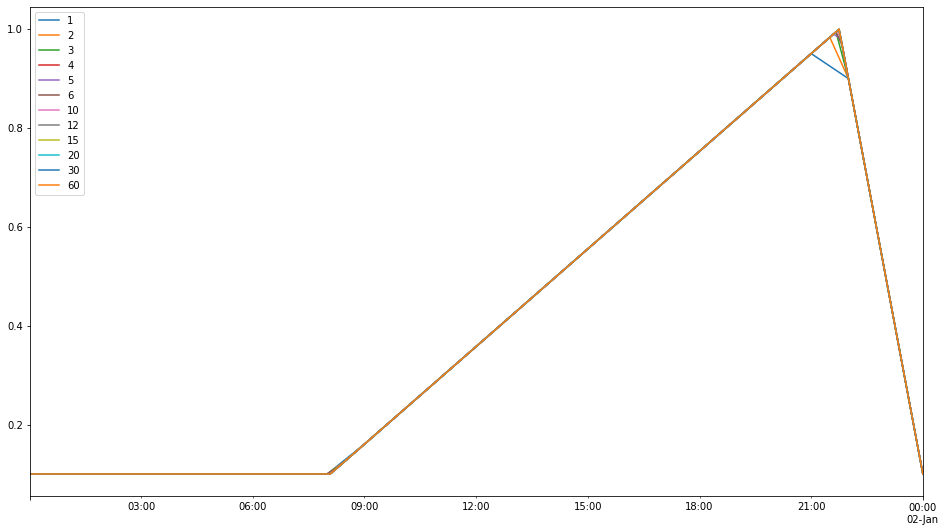

In [30]:
interp_method = 'Linear'
fig, ax = plt.subplots()
for t in TIMESTEPS:
    bigger_dict[t][interp_method].plot(ax=ax, label=t)
ax.legend()

## Misc to debug

In [31]:
def parse_sql(sql_path: Path) -> pd.Series:

    sql_uri = f'{sql_path.absolute().as_uri()}?mode=ro'
    print(f"{sql_uri=}")

    query = """
SELECT Month, Day, Hour, Minute,
       ReportingFrequency, KeyValue, Name, Units, Value
FROM ReportVariableWithTime
"""
# WHERE EnvironmentPeriodIndex=3
#    AND  Name='Zone Predicted Sensible Load to Setpoint Heat Transfer Rate'
#    AND KeyValue='ER_EXAM3_MULT4_FLR_1 ZN'

    with sqlite3.connect(sql_uri, uri=True) as con:
        df = pd.read_sql(query, con=con)

    return df
    # Here is my new way to do it, wall time is 22s
    filt = df['Hour'] == 24
    df.loc[filt, 'Hour'] = 23
    df.loc[filt, 'Minute'] = 59

    year = 2006
    df['Timestamp'] = pd.to_datetime((year*100000000 +
                                      df.Month*1000000 +
                                      df.Day*10000 +
                                      df.Hour*100 +
                                      df.Minute).apply(str),
                                     format='%Y%m%d%H%M')
    df.loc[filt, 'Timestamp'] += datetime.timedelta(minutes=1)

    df_pivot = pd.pivot_table(df, values='Value',
                                  columns=['ReportingFrequency', 'KeyValue',
                                           'Name', 'Units'],
                                  index=['Timestamp'])

    s = df_pivot.iloc[:, 0]
    s = s.head(143)
    return s

In [32]:
df = parse_sql(svg.sql_file)
assert df.shape[0] == 24 * svg.num_timesteps_per_hour

sql_uri='file:///Users/julien/Software/OpenStudio_to_EnergyPlusAPI/test_schedules/out-No-60/eplusout.sql?mode=ro'


In [33]:
df

,Month,Day,Hour,Minute,ReportingFrequency,KeyValue,Name,Units,Value
0,1,1,0,1,Zone Timestep,EXTERIOREQSCH,Schedule Value,,0.1
1,1,1,0,2,Zone Timestep,EXTERIOREQSCH,Schedule Value,,0.1
2,1,1,0,3,Zone Timestep,EXTERIOREQSCH,Schedule Value,,0.1
3,1,1,0,4,Zone Timestep,EXTERIOREQSCH,Schedule Value,,0.1
4,1,1,0,5,Zone Timestep,EXTERIOREQSCH,Schedule Value,,0.1
...,...,...,...,...,...,...,...,...,...
1435,1,1,23,56,Zone Timestep,EXTERIOREQSCH,Schedule Value,,0.1
1436,1,1,23,57,Zone Timestep,EXTERIOREQSCH,Schedule Value,,0.1
1437,1,1,23,58,Zone Timestep,EXTERIOREQSCH,Schedule Value,,0.1
1438,1,1,23,59,Zone Timestep,EXTERIOREQSCH,Schedule Value,,0.1
